# 08 — Prepare V3 multi-view data

This stage creates three complementary representations from the annotated red PPG:

- filtered PPG + first derivative + second derivative;
- compact log-power STFT;
- morphology, periodicity, beat-template, and spectral SQIs.

The original test subjects remain marked as audit-only.

In [1]:
from pathlib import Path
import os
import sys


def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "apps").exists():
            return candidate
    raise RuntimeError("Run this notebook inside the pure-pulsesure repository")


REPO_ROOT = find_repository_root(Path.cwd().resolve())
RAW_DIR = Path(os.environ.get("PURE_BUT_PPG_DIR", REPO_ROOT / "data" / "raw" / "but-ppg-2.0.0")).expanduser().resolve()
V3_DATA_DIR = Path(os.environ.get("PURE_V3_DATA_DIR", REPO_ROOT / "data" / "processed" / "but-ppg-v3")).expanduser().resolve()
V3_MODEL_DIR = Path(os.environ.get("PURE_V3_MODEL_DIR", REPO_ROOT / "models" / "production" / "v3")).expanduser().resolve()

print("Raw:", RAW_DIR)
print("V3 data:", V3_DATA_DIR)
print("V3 models:", V3_MODEL_DIR)

Raw: /mnt/home/gracewahyuni06/pure-pulsesure/data/raw/but-ppg-2.0.0
V3 data: /mnt/home/gracewahyuni06/pure-pulsesure/data/processed/but-ppg-v3
V3 models: /mnt/home/gracewahyuni06/pure-pulsesure/models/production/v3


In [2]:
import subprocess

subprocess.run(
    [
        sys.executable,
        str(REPO_ROOT / "scripts" / "prepare_but_ppg_v3.py"),
        "--raw-dir", str(RAW_DIR),
        "--output-dir", str(V3_DATA_DIR),
    ],
    check=True,
)

{
  "created_at_utc": "2026-10-20T07:12:05.765831+00:00",
  "dataset": "BUT PPG v2.0.0",
  "records": 3888,
  "waveform_shape": [
    3888,
    3,
    300
  ],
  "waveform_view_order": [
    "filtered_ppg",
    "first_derivative",
    "second_derivative"
  ],
  "stft_shape": [
    3888,
    1,
    32,
    15
  ],
  "sqi_shape": [
    3888,
    25
  ],
  "sqi_feature_names": [
    "raw_range",
    "raw_std",
    "perfusion_proxy",
    "clipping_ratio",
    "filtered_skewness",
    "filtered_excess_kurtosis",
    "first_derivative_rms",
    "second_derivative_rms",
    "zero_crossing_rate",
    "hjorth_mobility",
    "hjorth_complexity",
    "spectral_entropy",
    "pulse_band_power_ratio",
    "high_frequency_power_ratio",
    "spectral_purity",
    "dominant_frequency_hz",
    "autocorrelation_peak",
    "autocorrelation_bpm",
    "peak_count",
    "peak_interval_cv",
    "peak_bpm",
    "template_correlation",
    "peak_prominence_cv",
    "window_dominant_frequency_std",
    "window_

CompletedProcess(args=['/mnt/home/gracewahyuni06/pure-pulsesure/.venv/bin/python', '/mnt/home/gracewahyuni06/pure-pulsesure/scripts/prepare_but_ppg_v3.py', '--raw-dir', '/mnt/home/gracewahyuni06/pure-pulsesure/data/raw/but-ppg-2.0.0', '--output-dir', '/mnt/home/gracewahyuni06/pure-pulsesure/data/processed/but-ppg-v3'], returncode=0)

In [3]:
import json
import numpy as np

archive = np.load(V3_DATA_DIR / "v3_representations.npz")
manifest = json.loads((V3_DATA_DIR / "manifest.json").read_text())
print("Waveform:", archive["X_waveform"].shape)
print("STFT:", archive["X_stft"].shape)
print("SQI:", archive["X_sqi"].shape)
print("All finite:", all(np.isfinite(archive[name]).all() for name in ["X_waveform", "X_stft", "X_sqi"]))
manifest

Waveform: (3888, 3, 300)
STFT: (3888, 1, 32, 15)
SQI: (3888, 25)
All finite: True


{'created_at_utc': '2026-10-20T07:12:05.765831+00:00',
 'dataset': 'BUT PPG v2.0.0',
 'records': 3888,
 'waveform_shape': [3888, 3, 300],
 'waveform_view_order': ['filtered_ppg',
  'first_derivative',
  'second_derivative'],
 'stft_shape': [3888, 1, 32, 15],
 'sqi_shape': [3888, 25],
 'sqi_feature_names': ['raw_range',
  'raw_std',
  'perfusion_proxy',
  'clipping_ratio',
  'filtered_skewness',
  'filtered_excess_kurtosis',
  'first_derivative_rms',
  'second_derivative_rms',
  'zero_crossing_rate',
  'hjorth_mobility',
  'hjorth_complexity',
  'spectral_entropy',
  'pulse_band_power_ratio',
  'high_frequency_power_ratio',
  'spectral_purity',
  'dominant_frequency_hz',
  'autocorrelation_peak',
  'autocorrelation_bpm',
  'peak_count',
  'peak_interval_cv',
  'peak_bpm',
  'template_correlation',
  'peak_prominence_cv',
  'window_dominant_frequency_std',
  'window_pulse_power_std'],
 'preprocessing': {'sampling_rate_hz': 30.0,
  'low_cut_hz': 0.5,
  'high_cut_hz': 8.0,
  'filter_order'

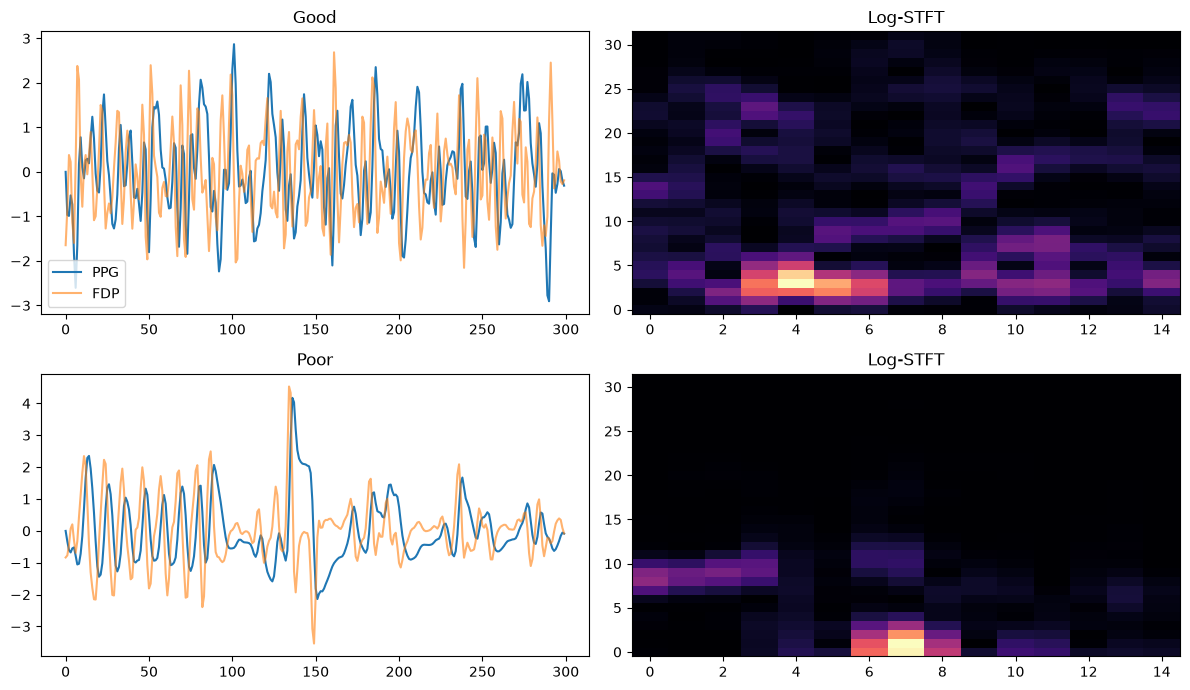

In [4]:
import matplotlib.pyplot as plt

y = archive["y"]
figure, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, label in enumerate([1, 0]):
    index = int(np.flatnonzero(y == label)[0])
    axes[row, 0].plot(archive["X_waveform"][index, 0], label="PPG")
    axes[row, 0].plot(archive["X_waveform"][index, 1], alpha=0.6, label="FDP")
    axes[row, 0].set_title("Good" if label else "Poor")
    axes[row, 1].imshow(archive["X_stft"][index, 0], origin="lower", aspect="auto", cmap="magma")
    axes[row, 1].set_title("Log-STFT")
axes[0, 0].legend()
plt.tight_layout()